In [1]:
from ultralytics import YOLO
from getpass import getpass
from roboflow import Roboflow
import shutil
import cv2

In [ ]:
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("jhazmine-therese-roque-biwst").project("emotion-detection-ooj7h")
dataset = project.version(4).download("yolov8", location="datasets/emotions")
print(dataset.location)

train: 4487 frames, 0 images without frames
{'Angry': 642, 'Disgusted': 644, 'Fearful': 634, 'Happy': 639, 'Neutral': 640, 'Sad': 640, 'Surprised': 648}
valid: 550 frames, 0 images without frames
{'Angry': 79, 'Disgusted': 78, 'Fearful': 83, 'Happy': 73, 'Neutral': 74, 'Sad': 85, 'Surprised': 78}
test: 566 frames, 0 images without frames
{'Angry': 80, 'Disgusted': 78, 'Fearful': 83, 'Happy': 91, 'Neutral': 85, 'Sad': 75, 'Surprised': 74}


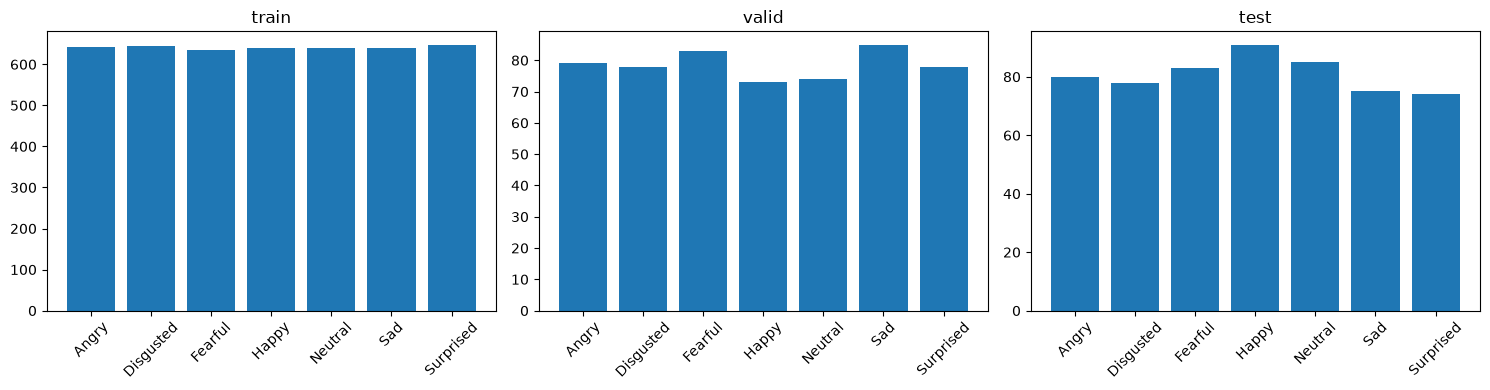

In [2]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

DATASET_DIR = Path("datasets/emotions")
NAMES = ["Angry", "Disgusted", "Fearful", "Happy", "Neutral", "Sad", "Surprised"]

def count_classes(split):
    counts, empty = Counter(), 0
    for f in (DATASET_DIR / split / "labels").glob("*.txt"):
        lines = f.read_text().strip().splitlines()
        if not lines:
            empty += 1
        for line in lines:
            counts[int(line.split()[0])] += 1
    return counts, empty

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, split in zip(axes, ["train", "valid", "test"]):
    counts, empty = count_classes(split)
    print(f"{split}: {sum(counts.values())} frames, {empty} images without frames")
    print({NAMES[i]: counts[i] for i in range(7)})
    ax.bar(NAMES, [counts[i] for i in range(7)])
    ax.set_title(split)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [3]:
def apply_clahe(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(2, 2))
    gray = clahe.apply(gray)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

In [4]:
PROCESSED_DIR = Path("datasets/emotions_clahe")

for split in ["train", "valid", "test"]:
    out_images = PROCESSED_DIR / split / "images"
    out_images.mkdir(parents=True, exist_ok=True)

    shutil.copytree(DATASET_DIR / split / "labels",
                    PROCESSED_DIR / split / "labels",
                    dirs_exist_ok=True)

    for path in (DATASET_DIR / split / "images").glob("*.jpg"):
        img = cv2.imread(str(path))
        cv2.imwrite(str(out_images / path.name), apply_clahe(img))

shutil.copy(DATASET_DIR / "data.yaml", PROCESSED_DIR / "data.yaml")
print("Ready")

Ready


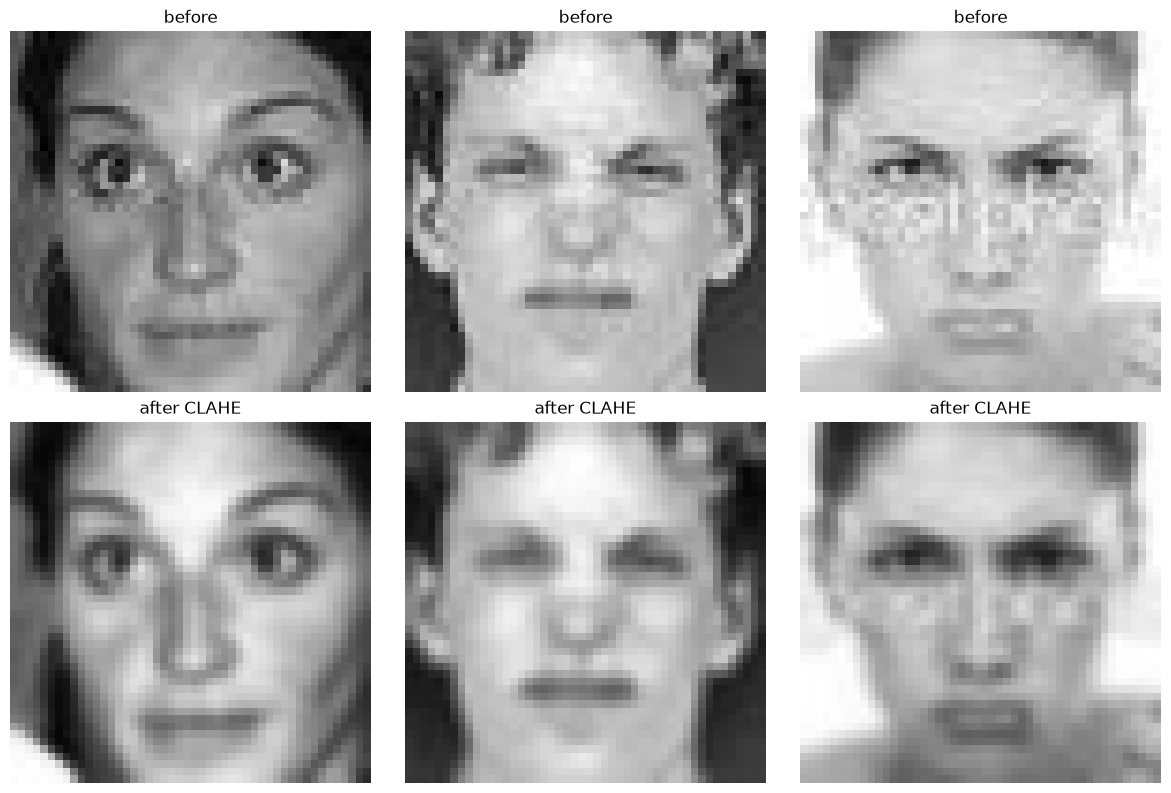

In [6]:
import random

random.seed(42)
files = random.sample(list((DATASET_DIR / "train" / "images").glob("*.jpg")), 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, path in enumerate(files):
    before = cv2.imread(str(path))
    after = cv2.imread(str(PROCESSED_DIR / "train" / "images" / path.name))
    axes[0, i].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title("before")
    axes[1, i].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[1, i].set_title("after CLAHE")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.savefig("preprocessing_example.png", dpi=100)
plt.show()